# Air Quality Index Prediction Using Historic Data
This project aims to develop a predictive model for estimating air quality index (AQI) based on various environmental factors.

## Importing Required Libraries
We start by importing essential libraries for data manipulation, visualization, and model training.

In [126]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [127]:


sns.set_theme(
    style="whitegrid",
    context="talk",
    palette="Set2"
)

plt.rcParams["figure.figsize"] = (11, 6)
plt.rcParams["axes.titlesize"] = 16
plt.rcParams["axes.labelsize"] = 13
plt.rcParams["xtick.labelsize"] = 11
plt.rcParams["ytick.labelsize"] = 11


## Loading and Exploring the Dataset
We load the dataset and perform initial exploration to understand its structure and characteristics.

In [128]:
file_path = "city_day.csv"  # Dataset source
df = pd.read_csv(file_path)

# Copy creating for experimenting
df_eda = df.copy()


In [129]:
#Dataset
df

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29526,Visakhapatnam,2020-06-27,15.02,50.94,7.68,25.06,19.54,12.47,0.47,8.55,23.30,2.24,12.07,0.73,41.0,Good
29527,Visakhapatnam,2020-06-28,24.38,74.09,3.42,26.06,16.53,11.99,0.52,12.72,30.14,0.74,2.21,0.38,70.0,Satisfactory
29528,Visakhapatnam,2020-06-29,22.91,65.73,3.45,29.53,18.33,10.71,0.48,8.42,30.96,0.01,0.01,0.00,68.0,Satisfactory
29529,Visakhapatnam,2020-06-30,16.64,49.97,4.05,29.26,18.80,10.03,0.52,9.84,28.30,0.00,0.00,0.00,54.0,Satisfactory


In [130]:
# Info of data 
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  object 
 1   Date        29531 non-null  object 
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  24850 non-null  object 
dtypes: float64(13), object(3)
memory usage: 3.6+ MB


## Data Preprocessing
This step involves handling missing values, encoding categorical features, and normalizing numerical features.

In [131]:
# Check the total null values
df.isnull().sum()

City              0
Date              0
PM2.5          4598
PM10          11140
NO             3582
NO2            3585
NOx            4185
NH3           10328
CO             2059
SO2            3854
O3             4022
Benzene        5623
Toluene        8041
Xylene        18109
AQI            4681
AQI_Bucket     4681
dtype: int64

In [132]:

# Handle missing values using MEAN on eda data , then we will do this on the real data

numeric_cols = df_eda.select_dtypes(include=["number"]).columns

df_eda[numeric_cols] = df_eda[numeric_cols].fillna(
    df_eda[numeric_cols].mean()
)


df_eda[numeric_cols].isnull().sum()

PM2.5      0
PM10       0
NO         0
NO2        0
NOx        0
NH3        0
CO         0
SO2        0
O3         0
Benzene    0
Toluene    0
Xylene     0
AQI        0
dtype: int64

In [133]:

df = df.dropna(subset=['AQI']).copy()

## Outliers using IQR


In [134]:

# Step 1: Detect outliers using IQR method
Q1 = df["AQI"].quantile(0.25)
Q3 = df["AQI"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df["AQI"] < lower_bound) | (df["AQI"] > upper_bound)]

print(f"Q1: {Q1:.2f}")
print(f"Q3: {Q3:.2f}")
print(f"IQR: {IQR:.2f}")
print(f"Lower Bound: {lower_bound:.2f}")
print(f"Upper Bound: {upper_bound:.2f}")
print(f"Total Outliers Found: {len(outliers)}")
print(f"Outlier Percentage: {(len(outliers)/len(df))*100:.2f}%")

# Step 2: Cap outliers at 99th percentile (Winsorization)
cap_value = df["AQI"].quantile(0.99)
df["AQI"] = df["AQI"].clip(upper=cap_value)

print(f"\nAQI capped at: {cap_value:.2f}")
print(f"New Maximum AQI: {df['AQI'].max():.2f}")
print(f"Outliers handled successfully.")


Q1: 81.00
Q3: 208.00
IQR: 127.00
Lower Bound: -109.50
Upper Bound: 398.50
Total Outliers Found: 1358
Outlier Percentage: 5.46%

AQI capped at: 661.51
New Maximum AQI: 661.51
Outliers handled successfully.


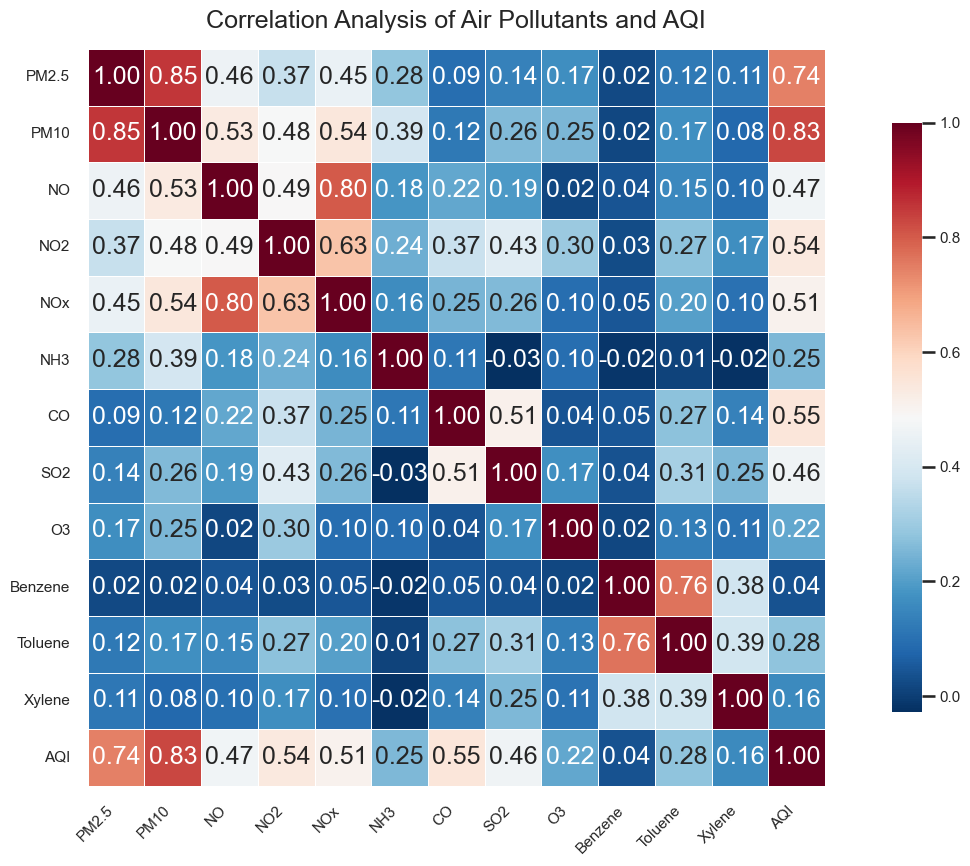

In [135]:

num_df = df.select_dtypes(include=['number'])


corr_matrix = num_df.corr()


plt.figure(figsize=(14, 9))
sns.heatmap(
    corr_matrix,
    annot=True, 
    fmt=".2f",
    cmap="RdBu_r",         
    linewidths=0.5,
    square=True,           
    cbar_kws={"shrink": 0.8}
)

plt.title("Correlation Analysis of Air Pollutants and AQI", fontsize=18, pad=15)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


## Exploratory Data Analysis (EDA)
We visualize the data to identify patterns, correlations, and important features.

In [136]:
numeric_cols_df = df.select_dtypes(include=['number']).columns
df[numeric_cols_df] = df[numeric_cols_df].fillna(df[numeric_cols_df].mean())

In [137]:
# Drop non-numeric and irrelevant columns
drop_columns = ['City', 'Date', 'AQI_Bucket']  
df = df.drop(columns=drop_columns)

In [138]:

target = 'AQI'
features = [col for col in df.columns if col != target]  #only features

X = df[features]  
y = df[target]  

## Splitting Data into Training and Testing Sets
We divide the dataset into training and test sets to evaluate model performance.

In [139]:
# Train Test Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Feature Scaling

In [140]:


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Choosing, Training and Evaluating the Models
We train multiple machine learning models and compare their performance.

In [141]:

models = {
    "Linear Regression": LinearRegression(),  
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),  
    "XGBoost": XGBRegressor(objective='reg:squarederror', n_estimators=100, random_state=42)  
}

In [142]:
# Train and Evaluate Models
results = {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)  
 
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    results[name] = {'MAE': mae, 'RMSE': rmse, 'R2 Score': r2} 
    print(f"{name} Performance:\nMAE: {mae:.2f}, RMSE: {rmse:.2f}, R2 Score: {r2:.2f}\n")

Linear Regression Performance:
MAE: 32.26, RMSE: 53.93, R2 Score: 0.80

Random Forest Performance:
MAE: 19.21, RMSE: 33.39, R2 Score: 0.92

XGBoost Performance:
MAE: 19.88, RMSE: 33.70, R2 Score: 0.92



In [143]:

xgb_model = models["XGBoost"]

feature_importance = xgb_model.feature_importances_

print("Number of features:", len(feature_importance))
print("Number of columns in X:", X.shape[1])


Number of features: 12
Number of columns in X: 12


In [144]:
# Convert results to DataFrame for better visualization
results_df = pd.DataFrame(results).T
print(results_df)

                         MAE       RMSE  R2 Score
Linear Regression  32.262022  53.926096  0.801273
Random Forest      19.211926  33.385311  0.923833
XGBoost            19.881370  33.696076  0.922408


## Model Performance Comparison

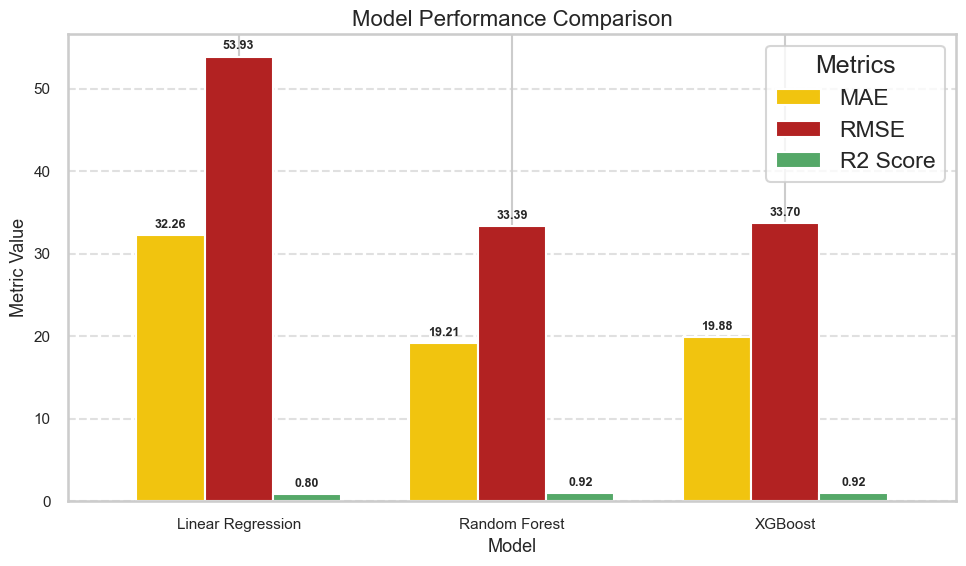

In [145]:
plt.figure(figsize=(10, 6))

ax = results_df.plot(
    kind="bar",
    width=0.75,
    color=["#F1C40F", "#B22222", "#55A868"],
    ax=plt.gca()
)

# Add values on top of each bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f",
        padding=3,
        fontsize=9,
        fontweight="bold"
    )

plt.title("Model Performance Comparison", fontsize=16)
plt.ylabel("Metric Value")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.legend(title="Metrics")
plt.tight_layout()
plt.show()

## Feature Importance Analysis

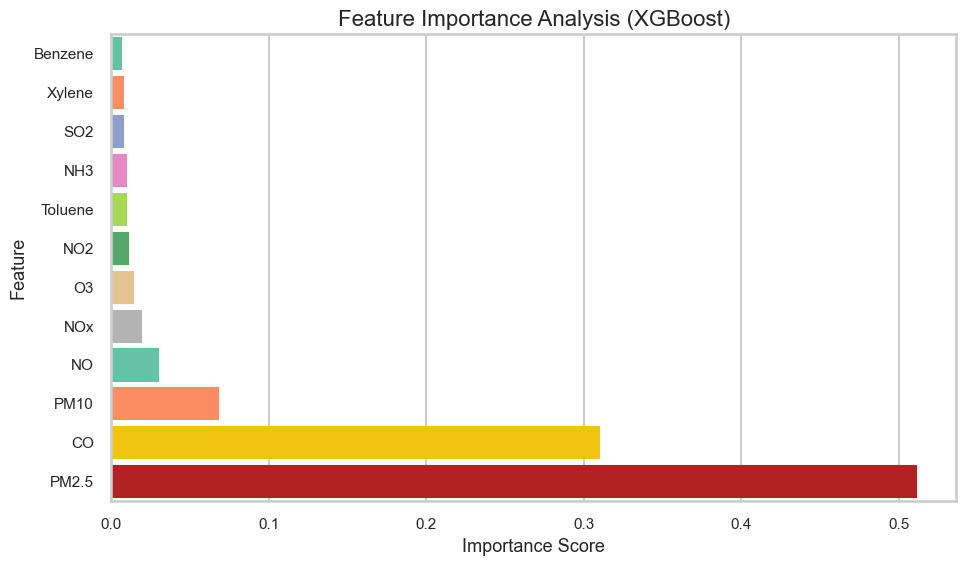

In [146]:


# Create dataframe
importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": feature_importance
}).sort_values(by="Importance", ascending=True)

# Plot WITHOUT palette or hue
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

# Base color cycle (all bars different)
base_colors = sns.color_palette("Set2", n_colors=len(importance_df))

# Apply colors manually
for bar, feature, color in zip(ax.patches, importance_df["Feature"], base_colors):
    if feature == "PM2.5":
        bar.set_color("#B22222")   # Firebrick
    elif feature == "CO":
        bar.set_color("#F1C40F")   # Golden Yellow
    elif feature == "NO2":
        bar.set_color("#55A868")   # Green
    else:
        bar.set_color(color)       # Other unique colors

plt.title("Feature Importance Analysis (XGBoost)", fontsize=16)
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


## Hyperparameter Tuning

In [147]:
# Hyperparameter Tuning for XGBoost
# Define parameter grid for tuning
tuning_params = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 5, 7]
}

In [148]:
# Perform grid search with cross-validation
grid_search = GridSearchCV(XGBRegressor(objective='reg:squarederror'), tuning_params, cv=5, scoring='r2')
grid_search.fit(X_train_scaled, y_train)
print(f"Best XGBoost Parameters: {grid_search.best_params_}")  # Output the best parameters

Best XGBoost Parameters: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200}


## Optimized Model Training and Evaluation

In [149]:
# Train the best XGBoost model with optimized parameters
best_xgb = XGBRegressor(
    objective='reg:squarederror',
    random_state=42,
    **grid_search.best_params_
)

best_xgb.fit(X_train_scaled, y_train)
y_pred_xgb = best_xgb.predict(X_test_scaled)


mae = mean_absolute_error(y_test, y_pred_xgb)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
r2 = r2_score(y_test, y_pred_xgb)

print(f"Optimized XGBoost Performance:\nMAE: {mae:.2f}, RMSE: {rmse:.2f}, R2 Score: {r2:.2f}")



Optimized XGBoost Performance:
MAE: 19.78, RMSE: 33.24, R2 Score: 0.92




## Making Predictions with the Trained Model

In [150]:
full_predictions = best_xgb.predict(X_test_scaled)
pred_df = pd.DataFrame({
    'Actual_AQI': y_test.values,
    'Predicted_AQI': full_predictions
})
pred_df.to_csv("aqi_predictions.csv", index=False)
print("Predictions saved to aqi_predictions.csv")

Predictions saved to aqi_predictions.csv


## Festive Vs Non-Festive AQI Prediction 🪔


In [151]:
# (EDA ONLY)



df_eda["Date"] = pd.to_datetime(df_eda["Date"])


diwali_dates = [
    ("2015-11-10", "2015-11-15"),
    ("2016-10-28", "2016-11-02"),
    ("2017-10-17", "2017-10-22"),
    ("2018-11-05", "2018-11-10"),
    ("2019-10-25", "2019-10-30")
]

# Create Festival column
df_eda["Festival"] = "Non-Festival"

for start, end in diwali_dates:
    df_eda.loc[
        (df_eda["Date"] >= start) & (df_eda["Date"] <= end),
        "Festival"
    ] = "Diwali"

# Quick check
df_eda["Festival"].value_counts()

Festival
Non-Festival    29093
Diwali            438
Name: count, dtype: int64

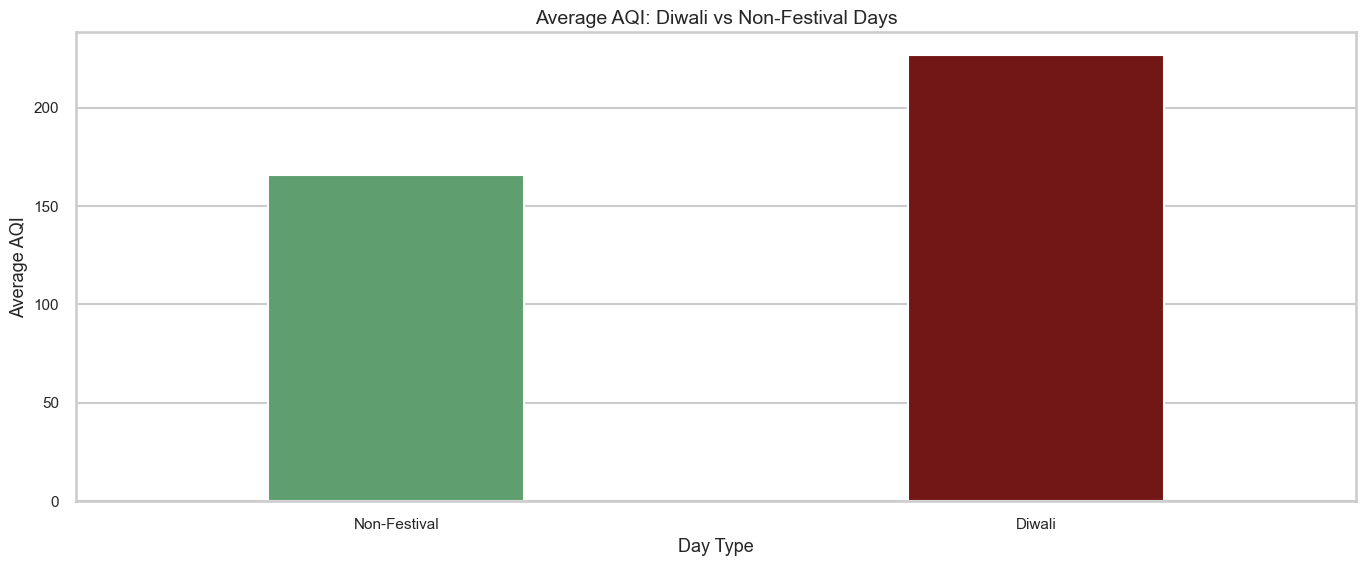

In [152]:
plt.figure(figsize=(14, 6))

sns.barplot(
    data=df_eda,
    x="Festival",
    y="AQI",
    hue="Festival",
    estimator="mean",
    errorbar=None,
    palette=["#55A868", "#820606"],
    legend=False,
    width=0.4
)

plt.title("Average AQI: Diwali vs Non-Festival Days", fontsize=14)
plt.xlabel("Day Type")
plt.ylabel("Average AQI")
plt.tight_layout()
plt.show()

In [153]:
def get_health_risk(aqi):
    if aqi <= 50:
        return "Good"
    elif aqi <= 100:
        return "Satisfactory"
    elif aqi <= 200:
        return "Moderate"
    elif aqi <= 300:
        return "Poor"
    elif aqi <= 400:
        return "Very Poor"
    else:
        return "Severe"


In [154]:
df_eda["Health_Risk"] = df_eda["AQI"].apply(
    lambda x: get_health_risk(x) if pd.notna(x) else None
)


In [155]:
df_eda["Health_Risk"].value_counts()


Health_Risk
Moderate        13510
Satisfactory     8224
Poor             2781
Very Poor        2337
Good             1341
Severe           1338
Name: count, dtype: int64

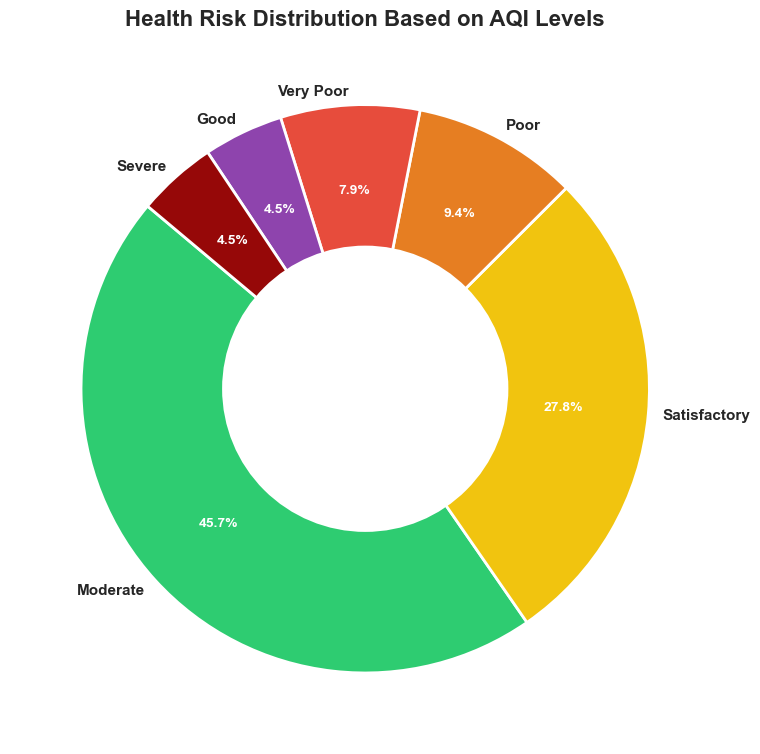

In [156]:
health_counts = df_eda["Health_Risk"].value_counts()

plt.figure(figsize=(8, 8))

wedges, texts, autotexts = plt.pie(
    health_counts,
    labels=health_counts.index,
    autopct="%1.1f%%",
    startangle=140,
    colors=["#2ECC71", "#F1C40F", "#E67E22", "#E74C3C", "#8E44AD", "#960808"],
    pctdistance=0.70,     # percentage INSIDE slices
    labeldistance=1.05,   # labels slightly outside but structured
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 11, "weight": "bold"}
)

# Make percentage text white for visibility
for autotext in autotexts:
    autotext.set_color("white")
    autotext.set_fontsize(10)

# Donut center
centre_circle = plt.Circle((0, 0), 0.50, fc="white")
plt.gca().add_artist(centre_circle)

plt.title("Health Risk Distribution Based on AQI Levels", fontsize=16, weight="bold")
plt.tight_layout()
plt.show()

##  AQI prediction🔮 using user input


In [157]:
# USER INPUT 
city_input = "Kolkata"   
month_input = 2  
year_input = 2026


In [158]:
# Filter data for selected city
city_data = df_eda[df_eda["City"] == city_input]

if city_data.empty:
    raise ValueError("City not found in dataset. Please enter a valid city.")


In [159]:
# Check if prediction is for future
max_year = df_eda["Date"].dt.year.max()
is_future = year_input > max_year


In [160]:
# Filter by selected month
monthly_data = city_data[city_data["Date"].dt.month == month_input]

if monthly_data.empty:
    raise ValueError("No data available for selected month.")

In [161]:
# Estimate pollutant levels for selected month
pollutants = ["PM2.5", "PM10", "NO2", "CO", "O3"]
pollutant_levels = monthly_data[pollutants].mean()

pollutant_levels


PM2.5    105.624386
PM10     194.508947
NO2       77.761404
CO         1.026316
O3        35.430175
dtype: float64

In [162]:
# -------------------------------
# Predict AQI using Trained XGBoost Model
# -------------------------------

# Step 1: Take monthly average of all features used during training
input_features = pd.DataFrame([monthly_data[features].mean()])

# Step 2: Check all required columns are present
missing_cols = [col for col in features if col not in input_features.columns]
if missing_cols:
    raise ValueError(f"Missing columns: {missing_cols}")

# Step 3: Scale using the SAME scaler used during training
input_scaled = scaler.transform(input_features)

# Step 4: Predict using optimized XGBoost model
estimated_aqi = best_xgb.predict(input_scaled)[0]

print(f"Input features used for prediction:")
print(input_features.T)
print(f"\nScaled successfully: {input_scaled.shape}")
print(f"Predicted AQI: {estimated_aqi:.1f}")

Input features used for prediction:
                  0
PM2.5    105.624386
PM10     194.508947
NO        50.056140
NO2       77.761404
NOx      120.849474
NH3       35.454035
CO         1.026316
SO2       15.268246
O3        35.430175
Benzene   10.860175
Toluene   17.084211
Xylene     3.065677

Scaled successfully: (1, 12)
Predicted AQI: 244.0


##  Output


In [163]:
risk_level = get_health_risk(estimated_aqi)

print(f"📍 City: {city_input}")
print(f"📅 Month-Year: {month_input}/{year_input}")
print(f"📊 Estimated AQI: {estimated_aqi:.1f}")
print(f"⚠️ Health Risk Level: {risk_level}")

if estimated_aqi > 200:
    print("🚨 Warning: High pollution expected. Avoid outdoor exposure.")
elif estimated_aqi > 100:
    print("⚠️ Caution: Sensitive groups should take precautions.")
else:
    print("✅ AQI expected to be acceptable.")


📍 City: Kolkata
📅 Month-Year: 2/2026
📊 Estimated AQI: 244.0
⚠️ Health Risk Level: Poor
🚨 Warning: High pollution expected. Avoid outdoor exposure.


## 🌍 Environmental & Health Impact

This dynamic AQI prediction system helps users make informed travel and health decisions by estimating future air quality based on historical seasonal patterns. It supports early warning mechanisms and aligns with the goals of Microsoft AI for Earth by promoting public health awareness and sustainable planning.


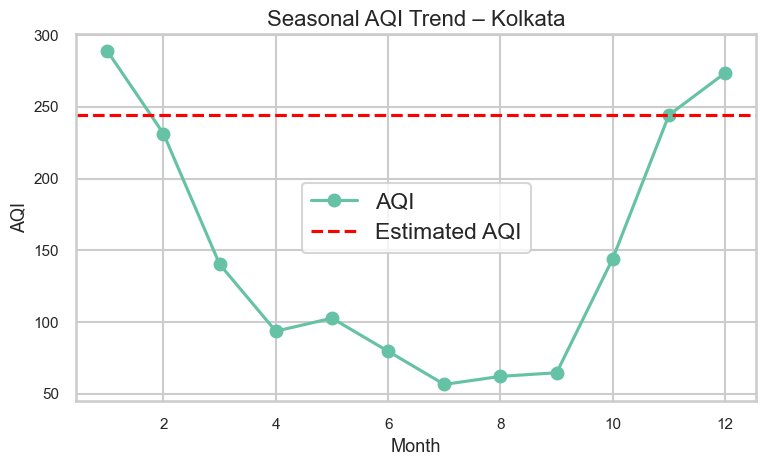

In [164]:
monthly_trend = city_data.groupby(
    city_data["Date"].dt.month
)["AQI"].mean()

plt.figure(figsize=(8, 5))
monthly_trend.plot(marker="o")
plt.axhline(estimated_aqi, color="red", linestyle="--", label="Estimated AQI")

plt.title(f"Seasonal AQI Trend – {city_input}")
plt.xlabel("Month")
plt.ylabel("AQI")
plt.legend()
plt.tight_layout()
plt.show()


## Actual vs. Predicted AQI Visualization

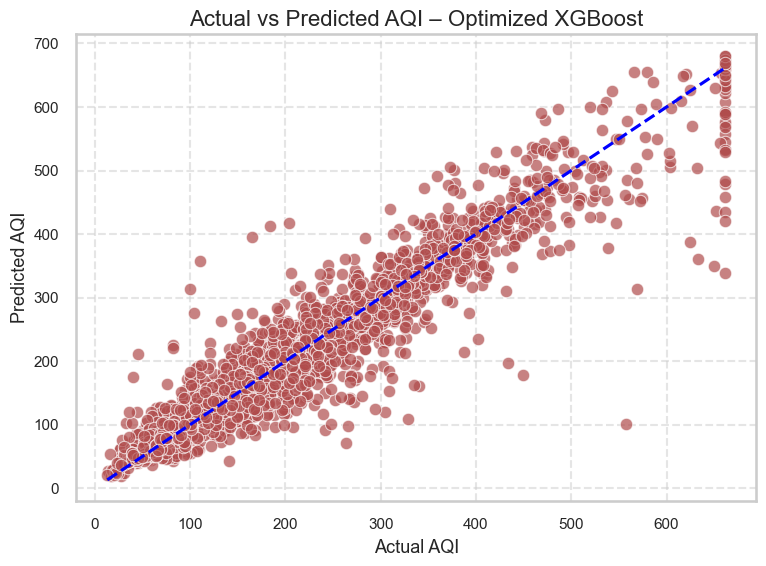

In [165]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test,
    y=y_pred_xgb,
    color="#B04C4C",
    alpha=0.7,
    s=80
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--",
    color="blue"
)

plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")
plt.title("Actual vs Predicted AQI – Optimized XGBoost", fontsize=16)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()